In [1]:
# Import-fix / M4
import sys, os
from pathlib import Path

WORK    = Path(r"D:\Projects\MediLens")
TRAINER = WORK / "EasyOCR" / "trainer"
config_path = TRAINER / "config_files" / "medical_prescription.yaml"
RESULTS = WORK / "results"; RESULTS.mkdir(exist_ok=True)
MODELS  = WORK / "models";  MODELS.mkdir(exist_ok=True)

# drop any wrongly-resolved modules, then put the trainer first on the path
for k in ("utils", "model", "dataset", "test", "train"):
    sys.modules.pop(k, None)
sys.path.insert(0, str(TRAINER))
os.chdir(TRAINER)

import utils
print(utils.__file__)                          # must end with ...\trainer\utils.py
from utils import AttrDict, CTCLabelConverter

D:\Projects\MediLens\EasyOCR\trainer\utils.py


In [2]:
# Setup and Helpers/ M8
import gc, numpy as np, pandas as pd, torch, yaml, easyocr
import torch.nn.functional as F
from PIL import Image
from nltk.metrics.distance import edit_distance
from utils import AttrDict, CTCLabelConverter
from model import Model

device = torch.device("cuda")
base = TRAINER / "all_data"

with open(config_path, encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character = opt.number + opt.symbol + opt.lang_char
ft_converter = CTCLabelConverter(opt.character)
opt.num_class = len(ft_converter.character)

test = pd.read_csv(base / "medical_test" / "labels.csv")
test["path"] = [str(base / "medical_test" / f) for f in test["filename"]]
train_names = sorted(set(pd.read_csv(base / "medical_train" / "labels.csv")["words"]))

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

def greedy(out, character):
    """standard CTC greedy decode: collapse repeats, then drop blanks (index 0)"""
    res = []
    for row in out.argmax(2).cpu().tolist():
        s, prev = [], 0
        for k in row:
            if k != 0 and k != prev:
                s.append(character[k])
            prev = k
        res.append("".join(s))
    return res

@torch.no_grad()
def run(model, converter, paths, vocab):
    """greedy decode + CTC-likelihood pick among `vocab`, for any recognizer"""
    v_text, v_len = converter.encode(vocab); V = len(vocab)
    raw, pick = [], []
    for i in range(0, len(paths), 64):
        x = torch.stack([prep(p) for p in paths[i:i+64]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        raw += greedy(out, converter.character)
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        in_len = torch.full((V,), T, dtype=torch.int32)
        for b in range(len(x)):
            lp = logp[b][:, None, :].expand(T, V, C).contiguous()
            nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0, reduction="none", zero_infinity=True)
            pick.append(vocab[int(nll.argmin())])
    return raw, pick

def load_ft(exp):
    m = torch.nn.DataParallel(Model(opt)).to(device)
    m.load_state_dict(torch.load(TRAINER / "saved_models" / exp / "best_accuracy.pth", map_location=device))
    return m.eval()

def zero_shot(reader, paths):
    """EasyOCR's own recognize() on the whole image, default settings"""
    out = []
    for p in paths:
        r = reader.recognize(np.array(Image.open(p).convert("L")), detail=0)
        out.append(r[0] if r else "")
    return out

def stats(preds, truths):
    ed = np.array([edit_distance(p, t) for p, t in zip(preds, truths)])
    L = np.array([len(t) for t in truths])
    ex = np.array([p == t for p, t in zip(preds, truths)])
    exi = np.array([p.lower() == t.lower() for p, t in zip(preds, truths)])
    return ed, L, ex, exi

def boot(ed, L, ex, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(ed), (n, len(ed)))
    cer = ed[idx].sum(1) / L[idx].sum(1)
    return np.percentile(cer, [2.5, 97.5]), np.percentile(ex[idx].mean(1), [2.5, 97.5])

def row(name, preds, truths):
    ed, L, ex, exi = stats(preds, truths)
    (c_lo, c_hi), (e_lo, e_hi) = boot(ed, L, ex)
    return {"system": name, "n": len(ed),
            "exact %": f"{ex.mean()*100:.1f} [{e_lo*100:.1f}, {e_hi*100:.1f}]",
            "exact, case-insens. %": f"{exi.mean()*100:.1f}",
            "CER": f"{ed.sum()/L.sum():.3f} [{c_lo:.3f}, {c_hi:.3f}]"}
print("test images:", len(test), "| vocabulary:", len(train_names))

test images: 780 | vocabulary: 78


In [3]:
# Closed-set table / Cell 31
truths = test["words"].tolist()
paths = test["path"].tolist()
rows = []

# 1) off-the-shelf EasyOCR, no fine-tuning
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
rows.append(row("EasyOCR pretrained, zero-shot (raw)", zero_shot(reader, paths), truths))
_, pick = run(reader.recognizer, reader.converter, paths, train_names)
rows.append(row("EasyOCR pretrained + vocab scoring", pick, truths))
del reader; gc.collect(); torch.cuda.empty_cache()

# 2) your fine-tuned models
for exp, label in [("medical_prescription", "Fine-tuned, run 1"),
                   ("medical_prescription_aug", "Fine-tuned, augmented")]:
    m = load_ft(exp)
    raw, pick = run(m, ft_converter, paths, train_names)
    rows.append(row(f"{label} (raw)", raw, truths))
    rows.append(row(f"{label} + vocab scoring", pick, truths))
    del m; gc.collect(); torch.cuda.empty_cache()

closed = pd.DataFrame(rows)
print(closed.to_string(index=False))
closed.to_csv(WORK / "results_closed_set.csv", index=False)

No Transformation module specified
No Transformation module specified
                               system   n           exact % exact, case-insens. %                  CER
  EasyOCR pretrained, zero-shot (raw) 780   8.6 [6.7, 10.8]                   9.9 0.567 [0.543, 0.589]
   EasyOCR pretrained + vocab scoring 780 76.0 [72.9, 79.1]                  76.0 0.192 [0.166, 0.216]
              Fine-tuned, run 1 (raw) 780 54.7 [51.2, 58.1]                  54.9 0.136 [0.123, 0.150]
    Fine-tuned, run 1 + vocab scoring 780 96.5 [95.1, 97.8]                  96.5 0.025 [0.016, 0.036]
          Fine-tuned, augmented (raw) 780 57.4 [54.0, 61.0]                  57.4 0.129 [0.115, 0.143]
Fine-tuned, augmented + vocab scoring 780 96.7 [95.4, 97.8]                  96.7 0.025 [0.016, 0.035]


In [4]:
# Held-out block / Cell 25
import gc

HOLDOUT = ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen']
hold = set(HOLDOUT)

parts = []
for split in ["medical_train", "medical_val", "medical_test"]:
    d = pd.read_csv(base / split / "labels.csv")
    d = d[d["words"].isin(hold)].copy()
    d["path"] = [str(base / split / f) for f in d["filename"]]
    parts.append(d)
held = pd.concat(parts, ignore_index=True)           # images of the 8 never-trained names
known = test[~test["words"].isin(hold)].copy()       # test images of the 70 trained names

vocab70 = sorted(set(train_names) - hold)
vocab78 = sorted(train_names)

m = load_ft("holdout")
raw_h, pick_h = run(m, ft_converter, held["path"].tolist(), vocab70)    # used by the open-set cell
raw_k, pick_k = run(m, ft_converter, known["path"].tolist(), vocab70)
held["raw"] = raw_h
known["raw"], known["pick"] = raw_k, pick_k

# added-names test: the same model, with the 8 unseen names appended to the vocabulary
_, pick_h78 = run(m, ft_converter, held["path"].tolist(), vocab78)
_, pick_k78 = run(m, ft_converter, known["path"].tolist(), vocab78)
del m; gc.collect(); torch.cuda.empty_cache()

def acc(p, df): return np.mean(np.array(p) == df["words"].values) * 100
print("sanity (earlier run: held-out raw CER 0.3356, known raw exact 56.86%):")
print("   held-out raw CER %.4f | known raw exact %.2f%%" % (
    sum(edit_distance(p, t) for p, t in zip(raw_h, held["words"])) / held["words"].str.len().sum(),
    np.mean(np.array(raw_k) == known["words"].values) * 100))
print("\nvocab = 70 trained names:      held-out images %.1f%% | known images %.1f%%" % (
    acc(pick_h, held), acc(pick_k, known)))
print("vocab = 78 (8 added, untrained): held-out images %.1f%% | known images %.1f%%" % (
    acc(pick_h78, held), acc(pick_k78, known)))

No Transformation module specified
sanity (earlier run: held-out raw CER 0.3356, known raw exact 56.86%):
   held-out raw CER 0.3356 | known raw exact 56.86%

vocab = 70 trained names:      held-out images 0.0% | known images 96.6%
vocab = 78 (8 added, untrained): held-out images 82.7% | known images 96.6%


held-out names: ['Bacmax', 'Lucan-R', 'Progut', 'Provair', 'Renova', 'Rivotril', 'Rozith', 'Tamen']
                                  system   n           exact % exact, case-insens. %                  CER
      Unseen names: pretrained zero-shot 480    4.6 [2.7, 6.5]                   5.4 0.619 [0.592, 0.645]
Unseen names: fine-tuned, never saw them 480 14.2 [11.0, 17.3]                  15.2 0.336 [0.317, 0.354]
       Known names: pretrained zero-shot 700   9.6 [7.6, 12.0]                  11.0 0.562 [0.537, 0.586]
 Known names: fine-tuned (holdout model) 700 56.9 [53.1, 60.6]                  57.0 0.127 [0.112, 0.141]
 threshold  unknown flagged %  unknown accepted wrongly %  known flagged %  accuracy on accepted known %
      0.10              100.0                         0.0             40.7                          97.1
      0.15              100.0                         0.0             30.1                          97.5
      0.20               99.6                         0

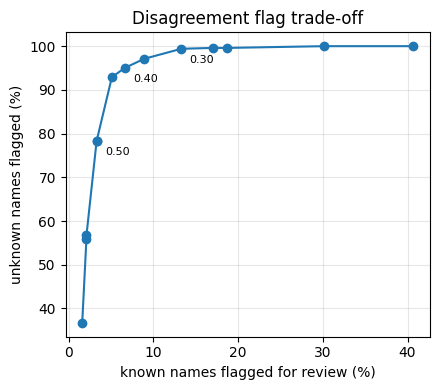

In [5]:
# Open-set comparison and flag sweep / Cell 32
import matplotlib.pyplot as plt
assert all(k in globals() for k in ("held", "known", "raw_h", "pick_h", "HOLDOUT")), \
    "re-run the held-out cells (Cell 1-3 of the open-set experiment) first"

# --- baseline on the same held-out and known-name images ---
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
zs_held = zero_shot(reader, held["path"].tolist())
zs_known = zero_shot(reader, known["path"].tolist())
del reader; gc.collect(); torch.cuda.empty_cache()

op = [
    row("Unseen names: pretrained zero-shot", zs_held, held["words"].tolist()),
    row("Unseen names: fine-tuned, never saw them", held["raw"].tolist(), held["words"].tolist()),
    row("Known names: pretrained zero-shot", zs_known, known["words"].tolist()),
    row("Known names: fine-tuned (holdout model)", known["raw"].tolist(), known["words"].tolist()),
]
openset = pd.DataFrame(op)
print("held-out names:", HOLDOUT)
print(openset.to_string(index=False))
openset.to_csv(WORK / "results_open_set.csv", index=False)

# --- flag trade-off: raw-vs-vocabulary disagreement ---
def dis(raw, pick):
    return np.array([edit_distance(r, p) / max(len(p), 1) for r, p in zip(raw, pick)])
dh = dis(raw_h, pick_h)
dk = dis(known["raw"], known["pick"])
pk, tk = np.array(known["pick"]), known["words"].values

sweep = []
for th in np.round(np.arange(0.1, 0.71, 0.05), 2):
    keep = dk <= th
    sweep.append({"threshold": th,
                  "unknown flagged %": 100 * np.mean(dh > th),
                  "unknown accepted wrongly %": 100 * np.mean(dh <= th),
                  "known flagged %": 100 * np.mean(dk > th),
                  "accuracy on accepted known %": 100 * np.mean(pk[keep] == tk[keep]) if keep.any() else np.nan})
sweep = pd.DataFrame(sweep)
other = [c for c in sweep.columns if c != "threshold"]
sweep[other] = sweep[other].round(1)
print(sweep.to_string(index=False))
sweep.to_csv(RESULTS / "results_flag_sweep.csv", index=False)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot(sweep["known flagged %"], sweep["unknown flagged %"], "o-")
for _, r in sweep.iterrows():
    if any(np.isclose(r["threshold"], t) for t in (0.3, 0.4, 0.5)):
        ax.annotate(f'{r["threshold"]:.2f}', (r["known flagged %"], r["unknown flagged %"]),
                    textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel("known names flagged for review (%)")
ax.set_ylabel("unknown names flagged (%)")
ax.set_title("Disagreement flag trade-off")
ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(RESULTS / "flag_tradeoff.png", dpi=300)
plt.show()

# Scaling Test

columns in file: ['name', 'type']
585 distractor names after cleaning | sample: [np.str_('Clomid'), np.str_('Aceclofenac'), np.str_('Isotretinoin'), np.str_('Lamisil'), np.str_('Prazosin'), np.str_('Mebeverine'), np.str_('Amiodarone'), np.str_('Flucloxacillin'), np.str_('Seroquel'), np.str_('Fosamax'), np.str_('Calbo'), np.str_('Doxycycline')]
No Transformation module specified
  32/830 images, 1s
  192/830 images, 4s
  352/830 images, 7s
  512/830 images, 10s
  672/830 images, 13s
  830/830 images, 16s
             vocab size  held mean  held std  known mean  known std  distractor_wins_known mean  distractor_wins_known std  distractor_wins_held mean  distractor_wins_held std
mode    N                                                                                                                                                                      
hardest 0            78       82.7       NaN        96.9        NaN                         0.0                        NaN                 

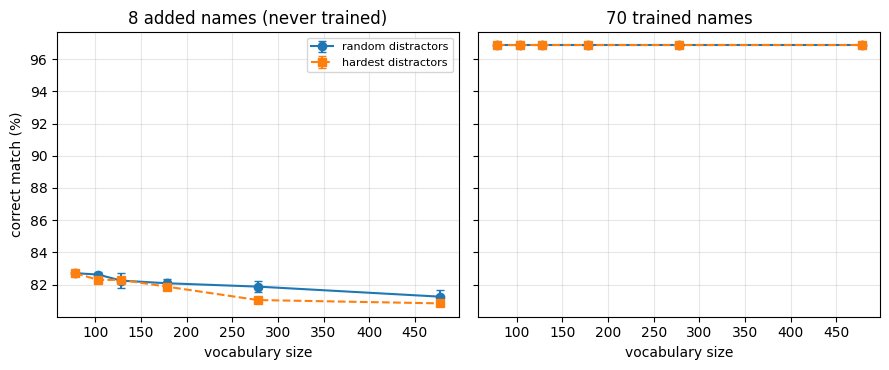

In [6]:
# Scaling test / Cell 35
import re, time
import matplotlib.pyplot as plt

# ---------------- EDIT THESE ----------------
VOCAB_FILE   = r"D:\Projects\MediLens\medicine_list_generated.csv"   # .csv or .txt, your list of medicine names
NAME_COLUMN  = None      # column with the names; None = first column
POOL_MAX     = 1000      # max distractor names to score
KNOWN_SAMPLE = 350       # known-name test images to use (all 700 = slower)
SIZES        = [0, 25, 50, 100, 200, 400]
DRAWS        = 5         # random distractor draws per size
# --------------------------------------------

# 1) load and clean the distractor pool
vf = Path(VOCAB_FILE)
if vf.suffix.lower() == ".txt":
    raw_names = vf.read_text(encoding="utf-8").splitlines()
else:
    dfv = pd.read_csv(vf, encoding="utf-8-sig")
    print("columns in file:", list(dfv.columns))
    raw_names = dfv[NAME_COLUMN or dfv.columns[0]].astype(str).tolist()

allowed = set(opt.character)
have = {n.lower() for n in vocab78}
seen, pool_names = set(), []
for n in raw_names:
    n = n.strip()
    if (2 <= len(n) <= 20 and re.fullmatch(r"[A-Za-z][A-Za-z\- ]*", n)
            and set(n) <= allowed and n.lower() not in have and n.lower() not in seen):
        seen.add(n.lower()); pool_names.append(n)
rng0 = np.random.default_rng(0)
if len(pool_names) > POOL_MAX:
    pool_names = [pool_names[i] for i in sorted(rng0.choice(len(pool_names), POOL_MAX, replace=False))]
print(f"{len(pool_names)} distractor names after cleaning | sample:", list(rng0.choice(pool_names, 12, replace=False)))
SIZES = [s for s in SIZES if s <= len(pool_names)]

# 2) images: the 8 added names + a sample of the 70 known names
known_s = known.sample(min(KNOWN_SAMPLE, len(known)), random_state=0)
paths  = held["path"].tolist() + known_s["path"].tolist()
truth  = np.array(held["words"].tolist() + known_s["words"].tolist(), dtype=object)
is_held = np.array([True] * len(held) + [False] * len(known_s))
names_all = list(vocab78) + pool_names
names_arr = np.array(names_all, dtype=object)
n78 = len(vocab78)

# 3) score every image against every name once (CTC negative log-likelihood)
@torch.no_grad()
def nll_matrix(model, paths, names, chunk=200):
    chunks = [names[i:i + chunk] for i in range(0, len(names), chunk)]
    enc = [ft_converter.encode(c) for c in chunks]
    M = np.zeros((len(paths), len(names)), dtype=np.float32)
    t0 = time.time()
    for i in range(0, len(paths), 32):
        x = torch.stack([prep(p) for p in paths[i:i + 32]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        for b in range(len(x)):
            col = 0
            for c_names, (v_text, v_len) in zip(chunks, enc):
                Vc = len(c_names)
                lp = logp[b][:, None, :].expand(T, Vc, C).contiguous()
                nll = F.ctc_loss(lp, v_text, torch.full((Vc,), T, dtype=torch.int32), v_len,
                                 blank=0, reduction="none", zero_infinity=True)
                M[i + b, col:col + Vc] = nll.numpy(); col += Vc
        if (i // 32) % 5 == 0:
            print(f"  {i + len(x)}/{len(paths)} images, {time.time() - t0:.0f}s")
    return M

m = load_ft("holdout")
M = nll_matrix(m, paths, names_all)
del m; gc.collect(); torch.cuda.empty_cache()
np.save(WORK / "scaling_nll.npy", M)       # keep it: re-analysing is then instant

# 4) accuracy as the vocabulary grows
def evaluate(cols):
    best = cols[M[:, cols].argmin(1)]
    ok = names_arr[best] == truth
    return {"held": ok[is_held].mean() * 100, "known": ok[~is_held].mean() * 100,
            "distractor_wins_known": (best[~is_held] >= n78).mean() * 100,
            "distractor_wins_held": (best[is_held] >= n78).mean() * 100}

base_idx, pool_idx = np.arange(n78), np.arange(n78, len(names_all))
res = []
for N in SIZES:                                   # random distractors
    for d in range(DRAWS if N else 1):
        cols = base_idx if N == 0 else np.concatenate(
            [base_idx, np.random.default_rng(100 + d).choice(pool_idx, N, replace=False)])
        res.append({"mode": "random", "N": N, "draw": d, **evaluate(cols)})

# worst case: distractors closest in spelling to the 78 real names
close = np.array([min(edit_distance(p.lower(), v.lower()) for v in vocab78) for p in pool_names])
order = pool_idx[np.argsort(close, kind="stable")]
for N in SIZES:
    cols = base_idx if N == 0 else np.concatenate([base_idx, order[:N]])
    res.append({"mode": "hardest", "N": N, "draw": 0, **evaluate(cols)})

R = pd.DataFrame(res)
summary = R.groupby(["mode", "N"]).agg(["mean", "std"]).round(1)
summary.columns = [f"{a} {b}" for a, b in summary.columns]
summary = summary[[c for c in summary.columns if not c.startswith("draw")]]
summary.insert(0, "vocab size", [78 + n for _, n in summary.index])
print(summary.to_string())
summary.to_csv(WORK / "results_scaling.csv")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, key, title in [(axes[0], "held", "8 added names (never trained)"), (axes[1], "known", "70 trained names")]:
    for mode, style in [("random", "o-"), ("hardest", "s--")]:
        s = R[R["mode"] == mode].groupby("N")[key].agg(["mean", "std"]).fillna(0)
        ax.errorbar(78 + s.index, s["mean"], yerr=s["std"], fmt=style, capsize=3, label=f"{mode} distractors")
    ax.set_title(title); ax.set_xlabel("vocabulary size"); ax.grid(alpha=.3)
axes[0].set_ylabel("correct match (%)"); axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(WORK / "scaling.png", dpi=300); plt.show()

No Transformation module specified
rows where both decoders agree on a different name: 23 of 1560


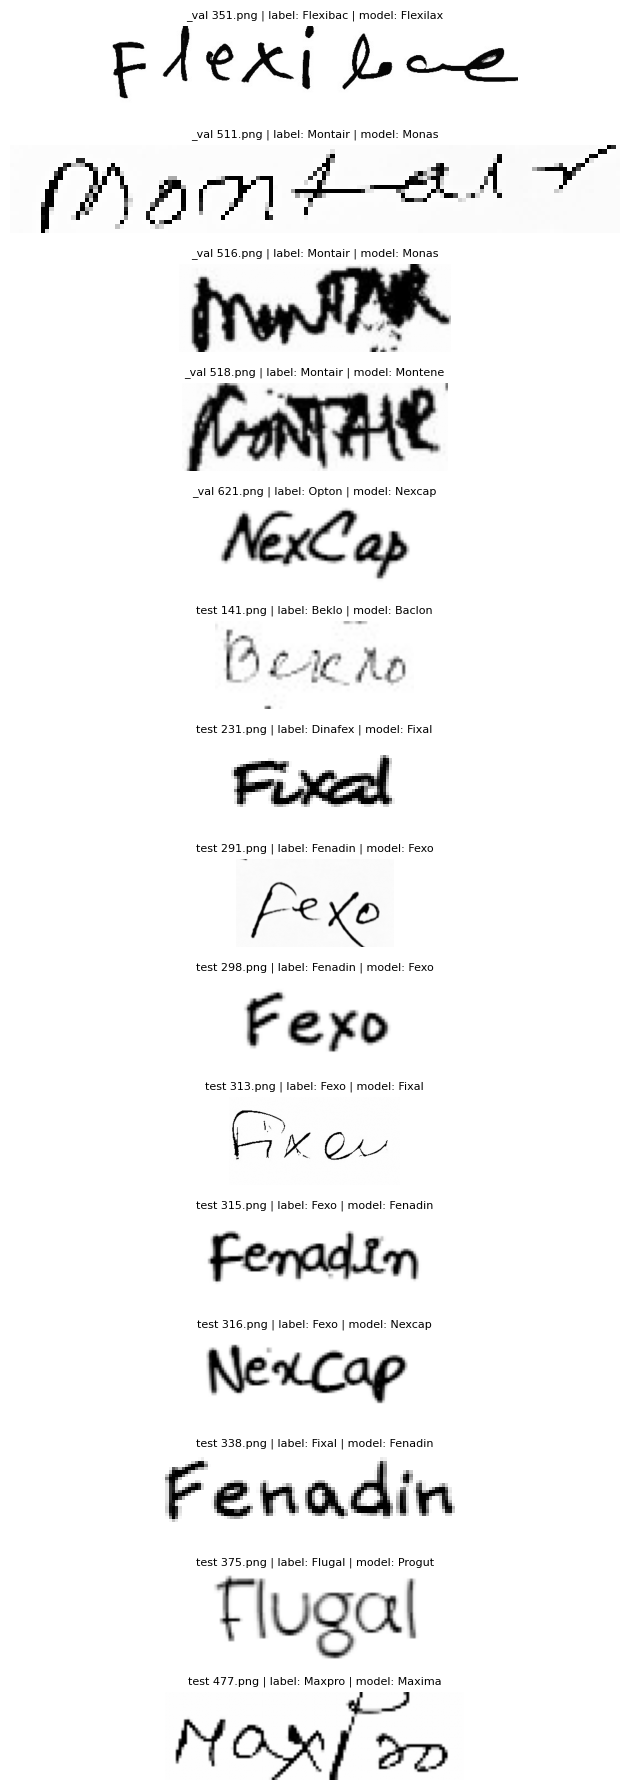

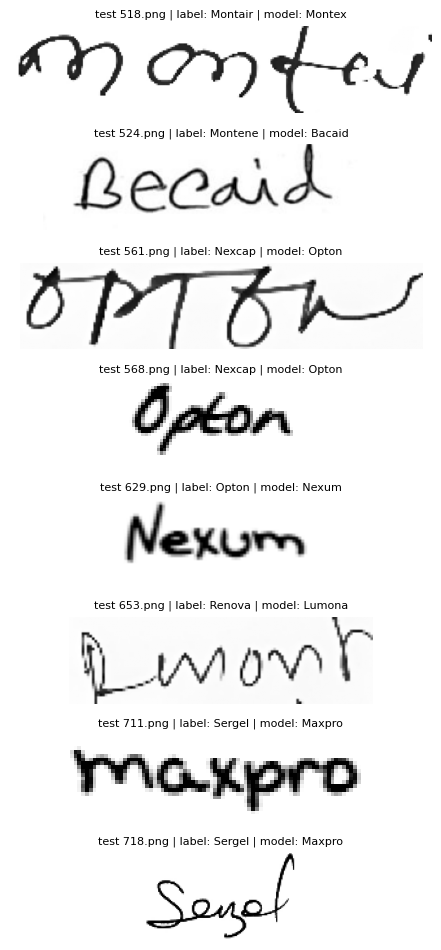

In [8]:
# Label audit / Cell 17
import matplotlib.pyplot as plt

m = load_ft("medical_prescription_aug")      # the final (augmented) model

def score_split(split):
    d = pd.read_csv(base / split / "labels.csv")
    paths_s = [str(base / split / f) for f in d["filename"]]
    raw, pick = run(m, ft_converter, paths_s, train_names)   # greedy + CTC vocab pick
    d["pred"], d["ctc_pred"], d["split"] = raw, pick, split
    return d

res = pd.concat([score_split("medical_val"), score_split("medical_test")], ignore_index=True)
del m; gc.collect(); torch.cuda.empty_cache()

# flag: raw decode snaps to the same name as the vocab pick, but that name differs from the label
snap = [train_names[int(np.argmin([edit_distance(r, n) for n in train_names]))] for r in res["pred"]]
res["snap_pred"] = snap
flag = res[(res["snap_pred"] == res["ctc_pred"]) & (res["ctc_pred"] != res["words"])].copy()
print("rows where both decoders agree on a different name:", len(flag), "of", len(res))
flag.to_csv(RESULTS / "flagged_labels.csv", index=False)

def show(rows, per_page=15):
    for s in range(0, len(rows), per_page):
        chunk = rows.iloc[s:s+per_page]
        fig, axes = plt.subplots(len(chunk), 1, figsize=(7, 1.2 * len(chunk)))
        axes = np.atleast_1d(axes)
        for ax, (_, r) in zip(axes, chunk.iterrows()):
            ax.imshow(Image.open(base / r["split"] / r["filename"]).convert("L"), cmap="gray")
            ax.set_title(f'{r["split"][-4:]} {r["filename"]} | label: {r["words"]} | model: {r["ctc_pred"]}', fontsize=8)
            ax.axis("off")
        plt.tight_layout(); plt.show()

show(flag)